In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Project paths
processed_dir = Path("../data/processed")
images_dir = Path("../images")

# Load saved crop trend data
crop_trends = pd.read_csv(
    processed_dir / "rice_wheat_trend_data.csv"
)

# Load rainfall summary created earlier
rainfall_trends = pd.read_csv(
    processed_dir / "annual_monsoon_summary.csv"
)

print("Crop data shape:", crop_trends.shape)
print("Rainfall data shape:", rainfall_trends.shape)

print("\nCrop columns:")
print(crop_trends.columns.tolist())

print("\nRainfall columns:")
print(rainfall_trends.columns.tolist())

display(crop_trends.head())
display(rainfall_trends.head())


Crop data shape: (46, 6)
Rainfall data shape: (117, 5)

Crop columns:
['Year', 'Crop', 'Total_Area_Hectares', 'Total_Production_Tonnes', 'Records', 'Yield_Tonnes_Per_Hectare']

Rainfall columns:
['YEAR', 'mean_rainfall', 'median_rainfall', 'std_rainfall', 'subdivisions_available']


,Year,Crop,Total_Area_Hectares,Total_Production_Tonnes,Records,Yield_Tonnes_Per_Hectare
0,1997-98,Rice,14511608.0,33337540.0,256,2.297302
1,1997-98,Wheat,26186026.0,64704641.0,403,2.470961
2,1998-99,Rice,24280749.0,47876569.0,375,1.971791
3,1998-99,Wheat,27195823.0,70672743.0,417,2.598662
4,1999-00,Rice,25744811.0,54909248.6,452,2.132828


,YEAR,mean_rainfall,median_rainfall,std_rainfall,subdivisions_available
0,1901,921.305714,700.9,653.026910,35
1,1902,1018.385714,811.2,762.621043,35
2,1903,1050.194286,866.8,639.341910,35
3,1904,933.874286,714.1,678.697194,35
4,1905,879.171429,805.4,608.763821,35


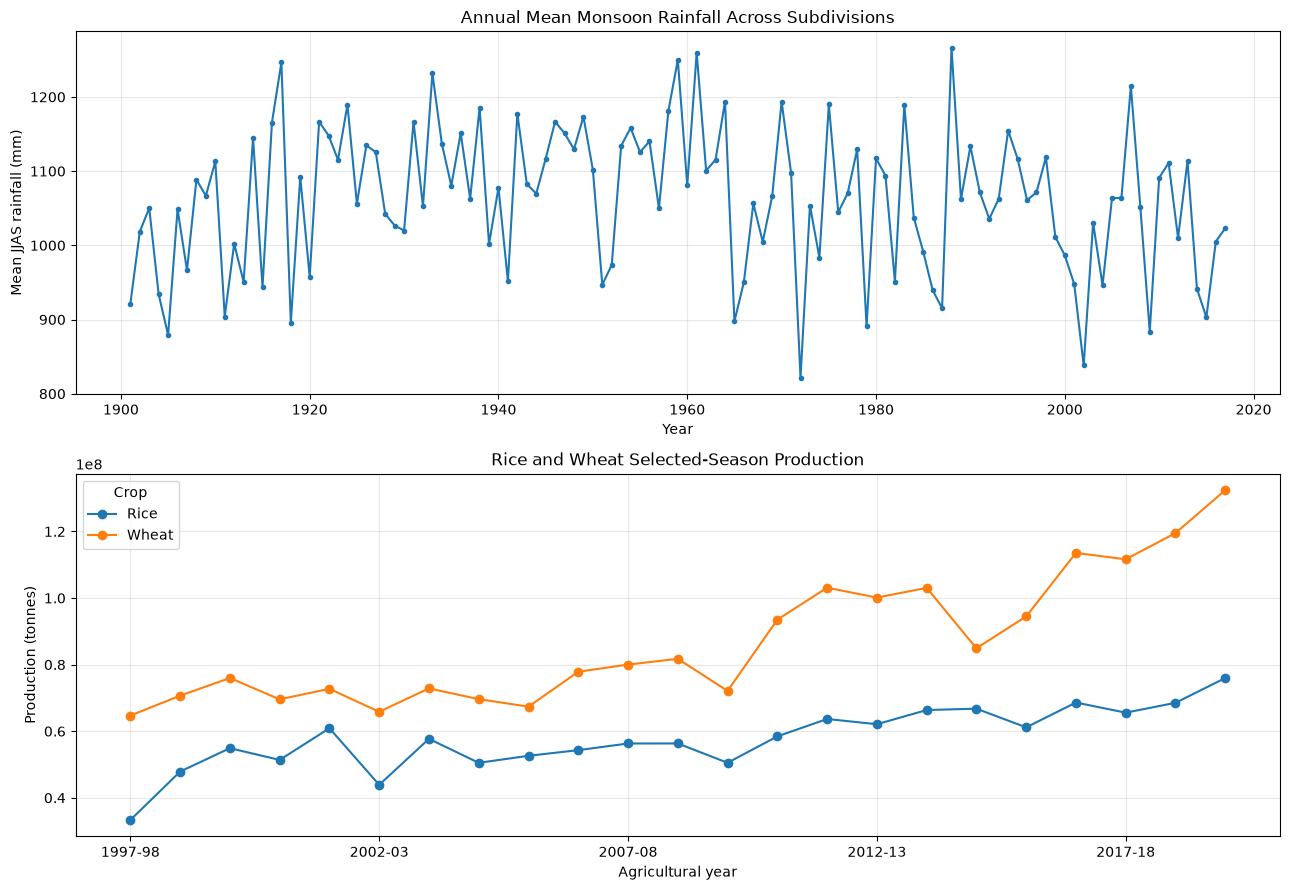

In [2]:

# Annual monsoon rainfall trend
rain = rainfall_trends.sort_values("YEAR").copy()

fig, axes = plt.subplots(2, 1, figsize=(13, 9))

axes[0].plot(
    rain["YEAR"],
    rain["mean_rainfall"],
    marker=".",
    linewidth=1.5
)
axes[0].set_title("Annual Mean Monsoon Rainfall Across Subdivisions")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Mean JJAS rainfall (mm)")
axes[0].grid(True, alpha=0.3)

# Rice and Wheat production trends
production_pivot = crop_trends.pivot(
    index="Year",
    columns="Crop",
    values="Total_Production_Tonnes"
).sort_index()

production_pivot.plot(
    ax=axes[1],
    marker="o",
    linewidth=1.5
)
axes[1].set_title("Rice and Wheat Selected-Season Production")
axes[1].set_xlabel("Agricultural year")
axes[1].set_ylabel("Production (tonnes)")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(
    images_dir / "rainfall_crop_trends_comparison.png",
    dpi=200
)
plt.show()
plt.close()


In [4]:

import pandas as pd
from pathlib import Path

# Load the saved crop trend data
crop_file = Path("../data/processed/rice_wheat_trend_data.csv")
analysis = pd.read_csv(crop_file)

# Exclude incomplete year, if present
analysis = analysis[
    analysis["Year"].astype(str) != "2020-21"
].copy()

# Sort agricultural years chronologically
analysis = analysis.sort_values("Year")

first_year = analysis["Year"].iloc[0]
last_year = analysis["Year"].iloc[-1]

for crop in ["Rice", "Wheat"]:
    crop_df = analysis[analysis["Crop"] == crop].sort_values("Year")

    if len(crop_df) < 2:
        print(f"Not enough data for {crop}")
        continue

    first = crop_df.iloc[0]
    last = crop_df.iloc[-1]

    production_change = (
        (last["Total_Production_Tonnes"] -
         first["Total_Production_Tonnes"])
        / first["Total_Production_Tonnes"] * 100
    )

    area_change = (
        (last["Total_Area_Hectares"] -
         first["Total_Area_Hectares"])
        / first["Total_Area_Hectares"] * 100
    )

    yield_change = (
        (last["Yield_Tonnes_Per_Hectare"] -
         first["Yield_Tonnes_Per_Hectare"])
        / first["Yield_Tonnes_Per_Hectare"] * 100
    )

    print(f"\n{crop}: {first_year} to {last_year}")
    print(f"Production change: {production_change:.2f}%")
    print(f"Area change: {area_change:.2f}%")
    print(f"Yield change: {yield_change:.2f}%")



Rice: 1997-98 to 2019-20
Production change: 127.89%
Area change: 86.03%
Yield change: 22.50%

Wheat: 1997-98 to 2019-20
Production change: 104.65%
Area change: 36.75%
Yield change: 49.65%


In [5]:

# Check the overlapping period before attempting a comparison

crop_years = sorted(analysis["Year"].astype(str).unique())
rainfall_years = sorted(rainfall_trends["YEAR"].astype(int).unique())

print("Crop year range:", crop_years[0], "to", crop_years[-1])
print("Rainfall calendar-year range:",
      rainfall_years[0], "to", rainfall_years[-1])

print("\nCrop year format examples:")
print(crop_years[:5])

print("\nRainfall year examples:")
print(rainfall_years[-10:])

print(
    "\nBefore merging, confirm how each agricultural year "
    "maps to the calendar year of its monsoon season."
)


Crop year range: 1997-98 to 2019-20
Rainfall calendar-year range: 1901 to 2017

Crop year format examples:
['1997-98', '1998-99', '1999-00', '2000-01', '2001-02']

Rainfall year examples:
[np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017)]

Before merging, confirm how each agricultural year maps to the calendar year of its monsoon season.
